In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


candidate_paths = [
    Path("data/processed/sample_learning_log_from_feishu.csv"),
    Path("../data/processed/sample_learning_log_from_feishu.csv"),
]

data_path = next(
    (path for path in candidate_paths if path.exists()),
    None,
)

if data_path is None:
    raise FileNotFoundError(
        "找不到转换后的模拟数据文件。"
        "请确认 data/processed/sample_learning_log_from_feishu.csv 已存在。"
    )

df = pd.read_csv(data_path)
df["date"] = pd.to_datetime(df["date"])

df.head()

,date,sleep_duration_hours,sleep_quality,study_hours,deep_focus_hours,phone_entertainment_hours,exercise_hours,class_load,focus_score,notes
0,2026-10-01,7.5,4,4.0,2.5,1.5,0.5,中,4,状态稳定
1,2026-10-02,6.5,3,3.0,1.5,3.0,0.0,高,3,作业较多
2,2026-10-03,8.0,5,5.0,3.5,1.0,1.0,低,5,周末学习状态较好
3,2026-10-04,7.0,4,4.5,2.0,2.0,0.5,中,4,正常上课
4,2026-10-05,5.5,2,2.5,1.0,4.0,0.0,高,2,睡眠不足


In [9]:
print("数据行数和列数：", df.shape)

print("\n各字段的数据类型：")
print(df.dtypes)

print("\n缺失值数量：")
print(df.isna().sum())

数据行数和列数： (5, 10)

各字段的数据类型：
date                         datetime64[us]
sleep_duration_hours                float64
sleep_quality                         int64
study_hours                         float64
deep_focus_hours                    float64
phone_entertainment_hours           float64
exercise_hours                      float64
class_load                              str
focus_score                           int64
notes                                   str
dtype: object

缺失值数量：
date                         0
sleep_duration_hours         0
sleep_quality                0
study_hours                  0
deep_focus_hours             0
phone_entertainment_hours    0
exercise_hours               0
class_load                   0
focus_score                  0
notes                        0
dtype: int64


In [10]:
numeric_columns = [
    "sleep_duration_hours",
    "sleep_quality",
    "study_hours",
    "deep_focus_hours",
    "phone_entertainment_hours",
    "exercise_hours",
    "focus_score",
]

df[numeric_columns].describe()

,sleep_duration_hours,sleep_quality,study_hours,deep_focus_hours,phone_entertainment_hours,exercise_hours,focus_score
count,5.000000,5.000000,5.000000,5.000000,5.000000,5.00000,5.000000
mean,6.900000,3.600000,3.800000,2.100000,2.300000,0.40000,3.600000
std,0.961769,1.140175,1.036822,0.961769,1.204159,0.41833,1.140175
min,5.500000,2.000000,2.500000,1.000000,1.000000,0.00000,2.000000
25%,6.500000,3.000000,3.000000,1.500000,1.500000,0.00000,3.000000
50%,7.000000,4.000000,4.000000,2.000000,2.000000,0.50000,4.000000
75%,7.500000,4.000000,4.500000,2.500000,3.000000,0.50000,4.000000
max,8.000000,5.000000,5.000000,3.500000,4.000000,1.00000,5.000000


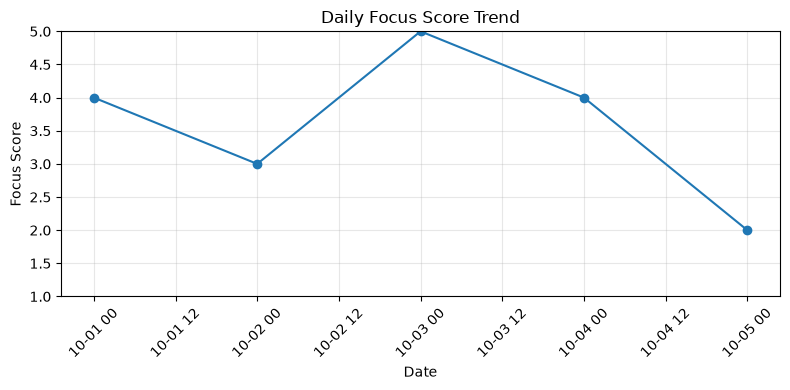

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(df["date"], df["focus_score"], marker="o")
plt.title("Daily Focus Score Trend")
plt.xlabel("Date")
plt.ylabel("Focus Score")
plt.ylim(1, 5)
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

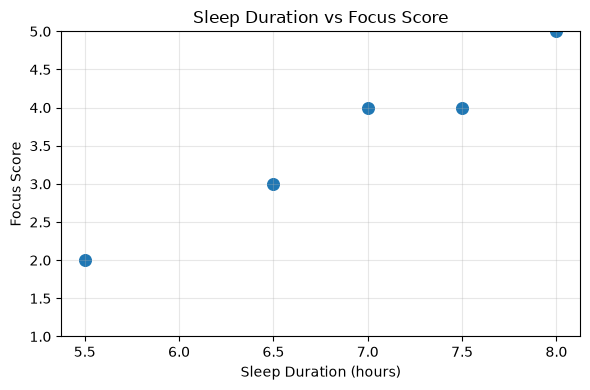

In [12]:
plt.figure(figsize=(6, 4))
plt.scatter(
    df["sleep_duration_hours"],
    df["focus_score"],
    s=70,
)

plt.title("Sleep Duration vs Focus Score")
plt.xlabel("Sleep Duration (hours)")
plt.ylabel("Focus Score")
plt.ylim(1, 5)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

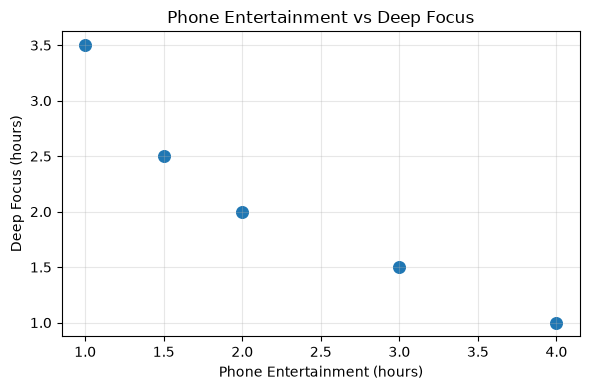

In [13]:
plt.figure(figsize=(6, 4))
plt.scatter(
    df["phone_entertainment_hours"],
    df["deep_focus_hours"],
    s=70,
)

plt.title("Phone Entertainment vs Deep Focus")
plt.xlabel("Phone Entertainment (hours)")
plt.ylabel("Deep Focus (hours)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

/var/folders/99/d4llk_dx3rx6g9gjxzpt9l240000gn/T/ipykernel_62329/3196588261.py:26: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/99/d4llk_dx3rx6g9gjxzpt9l240000gn/T/ipykernel_62329/3196588261.py:26: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/99/d4llk_dx3rx6g9gjxzpt9l240000gn/T/ipykernel_62329/3196588261.py:26: UserWarning: Glyph 39640 (\N{CJK UNIFIED IDEOGRAPH-9AD8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/s/Desktop/数据成长记/-/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/s/Desktop/数据成长记/-/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  

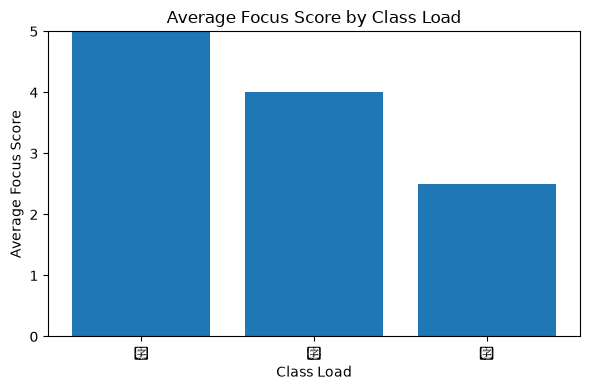

In [14]:
class_load_order = ["低", "中", "高"]

class_load_summary = (
    df.groupby("class_load", as_index=False)["focus_score"]
    .mean()
)

class_load_summary["class_load"] = pd.Categorical(
    class_load_summary["class_load"],
    categories=class_load_order,
    ordered=True,
)

class_load_summary = class_load_summary.sort_values("class_load")

plt.figure(figsize=(6, 4))
plt.bar(
    class_load_summary["class_load"].astype(str),
    class_load_summary["focus_score"],
)

plt.title("Average Focus Score by Class Load")
plt.xlabel("Class Load")
plt.ylabel("Average Focus Score")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

## 当前观察

本 Notebook 当前使用模拟飞书导出数据，主要用于展示 FocusFlow 的完整数据处理与分析流程。

在当前小样本模拟数据中，可以观察到：

1. 睡眠时长较高的日期，专注评分整体较高。
2. 娱乐手机时长较高的日期，深度学习时长可能偏低。
3. 课程负担较高时，专注评分可能出现更明显的波动。

以上结果仅展示当前样本中的关联现象，不能证明因果关系。后续需要积累更多真实个人记录，才能形成更稳定的观察。